# Task 2: Support Vector Machine (SVM)
Implement an SVM classifier, select a kernel, optimize the hyperparameters and check computational efficiency.

## Step 1: Import libraries

In [1]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

## Step 2: Load and prepare the data

In [2]:
df = pd.read_csv("employee_data_1.csv")

# fill missing values with median
df["Performance_Rating"] = df["Performance_Rating"].fillna(df["Performance_Rating"].median())
df["Training_Hours"] = df["Training_Hours"].fillna(df["Training_Hours"].median())

# target: High = 1, Low = 0
df["Satisfaction"] = df["Satisfaction"].map({"Low": 0, "High": 1})

# text columns -> numbers
df = pd.get_dummies(df, columns=["Department", "Education", "City_Tier"], drop_first=True)

X = df.drop("Satisfaction", axis=1)
y = df["Satisfaction"]
print("Features:", X.shape[1])
df.head()

Features: 18


,Age,Experience_Years,Performance_Rating,Weekly_Hours,Training_Hours,Certifications,Work_Life_Balance,Salary_LPA,Satisfaction,Department_Finance,Department_HR,Department_Marketing,Department_Operations,Department_Sales,Education_Diploma,Education_Masters,Education_PhD,City_Tier_Tier2,City_Tier_Tier3
0,41,17,2.4,42.0,56.0,0,5.0,25.00,1,False,False,True,False,False,False,False,True,True,False
1,39,13,3.7,49.0,12.0,2,3.1,19.41,0,False,False,False,False,True,False,False,False,False,False
2,24,2,3.5,45.0,8.0,2,3.9,8.41,0,False,False,False,True,False,True,False,False,False,True
3,26,0,3.7,34.0,5.0,1,4.0,19.83,0,True,False,False,False,False,False,True,False,False,False
4,44,19,3.8,40.0,56.0,0,3.2,28.35,1,False,False,False,False,False,False,False,False,True,False


## Step 3: Split and scale the data
SVM is based on distances, so scaling is very important.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# SVM and Logistic Regression need scaled data
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # learn scaling only from train data
X_test_s = scaler.transform(X_test)

print("Train:", X_train_s.shape, " Test:", X_test_s.shape)

Train: (1600, 18)  Test: (400, 18)


## Step 4: Basic SVM
First a simple SVM with default settings (rbf kernel).

In [4]:
svm_basic = SVC(random_state=42)
svm_basic.fit(X_train_s, y_train)
y_pred = svm_basic.predict(X_test_s)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("F1-score:", round(f1_score(y_test, y_pred), 4))

Accuracy: 0.8275
F1-score: 0.6425


## Step 5: Select the kernel
I test 4 kernels using 5-fold cross validation and also note the time taken.

In [5]:
kernels = ["linear", "poly", "rbf", "sigmoid"]
k_rows = []

for k in kernels:
    start = time.time()
    model = SVC(kernel=k, random_state=42)
    scores = cross_val_score(model, X_train_s, y_train, cv=5, scoring="accuracy")
    f1s = cross_val_score(model, X_train_s, y_train, cv=5, scoring="f1")
    end = time.time()

    k_rows.append({
        "Kernel": k,
        "CV Accuracy": scores.mean(),
        "CV F1-score": f1s.mean(),
        "Time (sec)": end - start,
    })

kernel_df = pd.DataFrame(k_rows).set_index("Kernel")
kernel_df.round(4)

,CV Accuracy,CV F1-score,Time (sec)
Kernel,,,
linear,0.8481,0.7033,0.4390
poly,0.8012,0.5389,0.4209
rbf,0.8369,0.6579,0.4435
sigmoid,0.8144,0.6344,0.5372


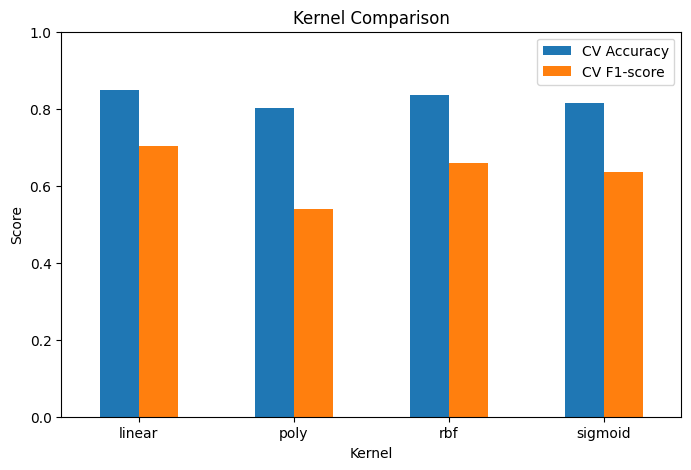

In [6]:
kernel_df[["CV Accuracy", "CV F1-score"]].plot(kind="bar", figsize=(8, 5))
plt.title("Kernel Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.show()

## Step 6: Tune the hyperparameters with GridSearchCV
`C` controls how strict the model is about errors and `gamma` controls how far one training point's influence reaches. I use the F1-score so the small High class is not ignored.

In [7]:
param_grid = {
    "kernel": ["linear", "rbf"],
    "C": [0.1, 1, 10, 100],
    "gamma": ["scale", 0.01, 0.1],   # gamma is ignored by the linear kernel
}

start = time.time()
grid = GridSearchCV(SVC(random_state=42), param_grid, cv=5, scoring="f1", n_jobs=-1)
grid.fit(X_train_s, y_train)
grid_time = time.time() - start

print("Best parameters:", grid.best_params_)
print("Best CV F1-score:", round(grid.best_score_, 4))
print("Grid search time:", round(grid_time, 2), "seconds")

Best parameters: {'C': 10, 'gamma': 'scale', 'kernel': 'linear'}
Best CV F1-score: 0.7064
Grid search time: 31.0 seconds


## Step 7: Evaluate the tuned SVM on the test data

In [8]:
best_svm = grid.best_estimator_
y_pred_best = best_svm.predict(X_test_s)

print("Accuracy:", round(accuracy_score(y_test, y_pred_best), 4))
print("F1-score:", round(f1_score(y_test, y_pred_best), 4))
print()
print(classification_report(y_test, y_pred_best, target_names=["Low", "High"]))
print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred_best))

Accuracy: 0.845
F1-score: 0.69

              precision    recall  f1-score   support

         Low       0.88      0.92      0.90       293
        High       0.74      0.64      0.69       107

    accuracy                           0.84       400
   macro avg       0.81      0.78      0.79       400
weighted avg       0.84      0.84      0.84       400

Confusion matrix:
[[269  24]
 [ 38  69]]


## Step 8: Computational efficiency
I check how long training takes when the training data size grows, and how scaling affects accuracy and time.

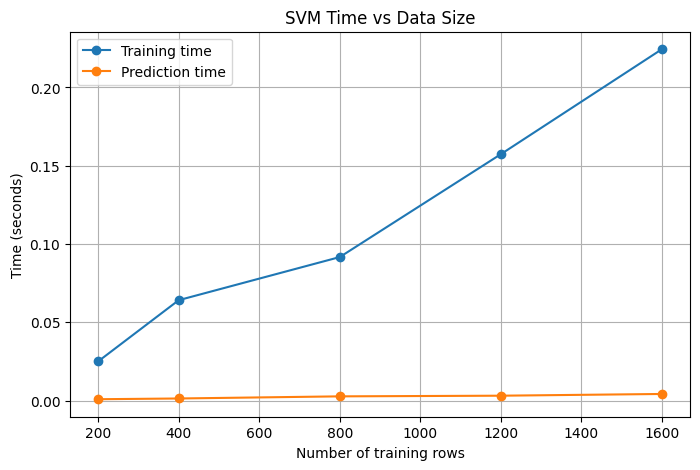

In [9]:
sizes = [200, 400, 800, 1200, 1600]
train_times = []
predict_times = []

for n in sizes:
    model = SVC(kernel=best_svm.kernel, C=best_svm.C, gamma=best_svm.gamma)

    start = time.time()
    model.fit(X_train_s[:n], y_train.iloc[:n])
    train_times.append(time.time() - start)

    start = time.time()
    model.predict(X_test_s)
    predict_times.append(time.time() - start)

plt.figure(figsize=(8, 5))
plt.plot(sizes, train_times, marker="o", label="Training time")
plt.plot(sizes, predict_times, marker="o", label="Prediction time")
plt.xlabel("Number of training rows")
plt.ylabel("Time (seconds)")
plt.title("SVM Time vs Data Size")
plt.legend()
plt.grid(True)
plt.show()

In [10]:
# with scaling vs without scaling
start = time.time()
m1 = SVC(kernel="rbf", C=1).fit(X_train, y_train)
t1 = time.time() - start
acc1 = accuracy_score(y_test, m1.predict(X_test))

start = time.time()
m2 = SVC(kernel="rbf", C=1).fit(X_train_s, y_train)
t2 = time.time() - start
acc2 = accuracy_score(y_test, m2.predict(X_test_s))

pd.DataFrame({
    "Accuracy": [acc1, acc2],
    "Training time (sec)": [t1, t2],
}, index=["Without scaling", "With scaling"]).round(4)

,Accuracy,Training time (sec)
Without scaling,0.7975,0.0563
With scaling,0.8275,0.0465


## Conclusion
- Kernel comparison: the linear kernel gave the best CV accuracy (about 0.85) and F1 (about 0.70), rbf was next, and poly was the worst. This suggests the classes are mostly separated by a straight boundary.
- GridSearchCV picked the linear kernel with C=10. On the test data it improved the basic SVM (accuracy 0.8275 to 0.845, F1 0.6425 to 0.69).
- Training time grows with the number of rows (about 0.02 sec for 200 rows to about 0.23 sec for 1600 rows), so SVM becomes slow on very large data. For this dataset it is still very fast. The grid search itself took about 30 seconds because it trains many models.
- Scaling the data matters for accuracy (0.7975 without scaling vs 0.8275 with scaling). It did not change the training time much here.